# Reading in the yellow taxis and the for-hire-vehicles (FHV) dataset

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import duckdb
import time
import numpy as np
import requests
import os
from io import BytesIO
from datetime import datetime
from pathlib import Path



**Pipeline:** Use Google Drive to persist monthly raw (unsampled) Parquet files so they don't disappear when runtime resets. After entering the date range, check to see if file for that month already exists. If not, download it from url.

DuckDB runs in memory and creates temporary SQL views for the selected months only. For now, .duckdb files are not maintained, but we can look into materializing frequently used or computationally expensive query results into persistent DuckDB tables in the future to avoid redundant processing and improve performance.


**MyDrive/CIS5450_GroupProject/**

> **taxi_data/** - Original, full Parquet files
  - e.g. yellow_tripdata_2024-08.parquet



**Data flow:** Raw (unsampled) monthly Parquet files in Google Drive → sampled Parquet files in Colab runtime → yellow_taxi and fhvhv in-memory views → combined_trips → duck_clean_df → df_cleaned.

In [ ]:
# Google Drive stores raw (unsampled) Parquet files
# Colab runtime stores sample files

from google.colab import drive
drive.mount('/content/drive')

DATA_FOLDER = Path('/content/drive/MyDrive/CIS5450_GroupProject/taxi_data')
SAMPLE_FOLDER = Path('/content/taxi_samples')
DATA_FOLDER.mkdir(parents=True, exist_ok=True)
SAMPLE_FOLDER.mkdir(parents=True, exist_ok=True)

SAMPLE_SIZE = 5000
RANDOM_SEED = 42

print('Raw files (persistent):', DATA_FOLDER)
print('Samples (runtime only):', SAMPLE_FOLDER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw files (persistent): /content/drive/MyDrive/CIS5450_GroupProject/taxi_data
Samples (runtime only): /content/taxi_samples


In [ ]:
# Ask the user for the start and end months
start_input = input("Enter start month (YYYY-MM): ")
end_input = input("Enter end month (YYYY-MM): ")

# Convert inputs to dates
start_date = datetime.strptime(start_input, "%Y-%m")
end_date = datetime.strptime(end_input, "%Y-%m")

# Validate the range
if start_date > end_date:
    raise ValueError("Start month must be before or equal to end month.")

# Generate every month in the range, inclusive
yellow_urls = []
fhv_urls = []

year = start_date.year
month = start_date.month

while (year, month) <= (end_date.year, end_date.month):
    #yellow taxi data
    yellow_urls.append(
        f"https://d37ci6vzurychx.cloudfront.net/trip-data/"
        f"yellow_tripdata_{year}-{month:02d}.parquet"
    )

    #for-hire / ride-share data
    fhv_urls.append(
        f"https://d37ci6vzurychx.cloudfront.net/trip-data/"
        f"fhvhv_tripdata_{year}-{month:02d}.parquet"
    )

    # Move to the next month
    if month == 12:
        year += 1
        month = 1
    else:
        month += 1

print(f"\nCreated {len(yellow_urls)} yellow cab monthly URLs and {len(fhv_urls)} for-hire vehicles months URLs.")

# for url in yellow_urls:
#     print(url)

# for url in fhv_urls:
#     print(url)

cab_urls = []
cab_urls = yellow_urls + fhv_urls
for url in cab_urls:
  print(url)



Enter start month (YYYY-MM): 2024-08
Enter end month (YYYY-MM): 2026-08

Created 25 yellow cab monthly URLs and 25 for-hire vehicles months URLs.
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-08.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-09.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-10.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-11.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-12.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-01.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-02.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-03.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-04.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2025-05.parquet
https://d37ci6vzurychx.cloudfront.net/trip-data/yellow

In [ ]:
# Download any missing full monthly files to Google Drive.
import requests
from pathlib import Path

# Download any missing full Parquet files to Google Drive
for url in cab_urls:
    filename = Path(url).name
    raw_file = DATA_FOLDER / filename

    # Skip files that already exist in Google Drive
    if raw_file.exists() and raw_file.stat().st_size > 0:
        print(f"Already downloaded: {filename}")
        continue

    # Download missing files
    print(f"Downloading: {filename}")

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    with open(raw_file, "wb") as f:
        f.write(response.content)

    print(f"Saved: {filename}")


Already downloaded: yellow_tripdata_2024-08.parquet
Already downloaded: yellow_tripdata_2024-09.parquet
Already downloaded: yellow_tripdata_2024-10.parquet
Already downloaded: yellow_tripdata_2024-11.parquet
Already downloaded: yellow_tripdata_2024-12.parquet
Already downloaded: yellow_tripdata_2025-01.parquet
Already downloaded: yellow_tripdata_2025-02.parquet
Already downloaded: yellow_tripdata_2025-03.parquet
Already downloaded: yellow_tripdata_2025-04.parquet
Already downloaded: yellow_tripdata_2025-05.parquet
Already downloaded: yellow_tripdata_2025-06.parquet
Already downloaded: yellow_tripdata_2025-07.parquet
Already downloaded: yellow_tripdata_2025-08.parquet
Already downloaded: yellow_tripdata_2025-09.parquet
Already downloaded: yellow_tripdata_2025-10.parquet
Already downloaded: yellow_tripdata_2025-11.parquet
Already downloaded: yellow_tripdata_2025-12.parquet
Already downloaded: yellow_tripdata_2026-01.parquet
Already downloaded: yellow_tripdata_2026-02.parquet
Already down

Commented out the below cell for now since the files persisted here seem to be tied to the runtime only and disappear if you change your runtime.

In [ ]:
#make the temporary folder for the data and put the parquet files there
# os.makedirs("taxi_data", exist_ok=True)

# for url in cab_urls:
#     filename = os.path.join("taxi_data", url.split("/")[-1])

#     if not os.path.exists(filename):
#         print("Downloading", filename)

#         r = requests.get(url)
#         r.raise_for_status()

#         with open(filename, "wb") as f:
#             f.write(r.content)

In [ ]:
# Generate Yellow Taxi samples for selected months in Colab runtime
con = duckdb.connect()  # In-memory only - no .duckdb file

for url in yellow_urls:
    raw_file = DATA_FOLDER / Path(url).name
    sample_file = SAMPLE_FOLDER / f"{raw_file.stem}_sample.parquet"
    if not raw_file.is_file():
        raise FileNotFoundError(f"Missing raw file: {raw_file}")

    # Replace any previous sample for this selected month.
    sample_file.unlink(missing_ok=True)

    input_path = str(raw_file).replace("'", "''")
    output_path = str(sample_file).replace("'", "''")
    con.execute(f"""
        COPY (
            WITH filtered_data AS (
                SELECT * FROM read_parquet('{input_path}')
                WHERE trip_distance > 0
                  AND total_amount > 0
                  AND passenger_count > 0
                  AND payment_type <> 4
                  AND PULocationID <> 265
                  AND DOLocationID <> 265
            )
            SELECT * FROM filtered_data USING SAMPLE {SAMPLE_SIZE} ROWS (reservoir, {RANDOM_SEED})
        ) TO '{output_path}' (FORMAT PARQUET)
    """)
    print(f"Saved sample: {sample_file.name}")

Saved sample: yellow_tripdata_2024-08_sample.parquet
Saved sample: yellow_tripdata_2024-09_sample.parquet
Saved sample: yellow_tripdata_2024-10_sample.parquet
Saved sample: yellow_tripdata_2024-11_sample.parquet
Saved sample: yellow_tripdata_2024-12_sample.parquet
Saved sample: yellow_tripdata_2025-01_sample.parquet
Saved sample: yellow_tripdata_2025-02_sample.parquet
Saved sample: yellow_tripdata_2025-03_sample.parquet
Saved sample: yellow_tripdata_2025-04_sample.parquet
Saved sample: yellow_tripdata_2025-05_sample.parquet
Saved sample: yellow_tripdata_2025-06_sample.parquet
Saved sample: yellow_tripdata_2025-07_sample.parquet
Saved sample: yellow_tripdata_2025-08_sample.parquet
Saved sample: yellow_tripdata_2025-09_sample.parquet
Saved sample: yellow_tripdata_2025-10_sample.parquet
Saved sample: yellow_tripdata_2025-11_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: yellow_tripdata_2025-12_sample.parquet
Saved sample: yellow_tripdata_2026-01_sample.parquet
Saved sample: yellow_tripdata_2026-02_sample.parquet
Saved sample: yellow_tripdata_2026-03_sample.parquet
Saved sample: yellow_tripdata_2026-04_sample.parquet
Saved sample: yellow_tripdata_2026-05_sample.parquet
Saved sample: yellow_tripdata_2026-06_sample.parquet
Saved sample: yellow_tripdata_2026-07_sample.parquet
Saved sample: yellow_tripdata_2026-08_sample.parquet


In [ ]:
# Regenerate FHVHV samples for selected months in Colab runtime.
for url in fhv_urls:
    raw_file = DATA_FOLDER / Path(url).name
    sample_file = SAMPLE_FOLDER / f"{raw_file.stem}_sample.parquet"
    if not raw_file.is_file():
        raise FileNotFoundError(f"Missing raw file: {raw_file}")

    # Replace any previous sample for this selected month.
    sample_file.unlink(missing_ok=True)

    input_path = str(raw_file).replace("'", "''")
    output_path = str(sample_file).replace("'", "''")
    con.execute(f"""
        COPY (
            WITH filtered_data AS (
                SELECT * FROM read_parquet('{input_path}')
                WHERE trip_miles > 0
                  AND PULocationID <> 265
                  AND DOLocationID <> 265
            )
            SELECT * FROM filtered_data USING SAMPLE {SAMPLE_SIZE} ROWS (reservoir, {RANDOM_SEED})
        ) TO '{output_path}' (FORMAT PARQUET)
    """)
    print(f"Saved sample: {sample_file.name}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2024-08_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2024-09_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

Saved sample: fhvhv_tripdata_2026-06_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2026-07_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2026-08_sample.parquet


In [ ]:
#Runtime-only version

# con = duckdb.connect()

# # data_folder = DATA_FOLDER
# # sample_folder = SAMPLE_FOLDER

# # Source files on your current working directory / Drive
# data_folder = Path("taxi_data")
# sample_folder = Path("taxi_samples")
# sample_folder.mkdir(parents=True, exist_ok=True)

# files = sorted(data_folder.glob("yellow*.parquet"))

# print(f"Found {len(files)} files")

# for file in files:
#     output_file = sample_folder / f"{file.stem}_sample.parquet"

#     # Skip files already sampled, useful if Colab crashes
#     if output_file.exists():
#         print(f"Skipping existing sample: {file.name}")
#         continue

#     # Escape single quotes in paths for SQL
#     input_path = str(file.resolve()).replace("'", "''")
#     output_path = str(output_file.resolve()).replace("'", "''")

#     query = f"""
#         COPY (
#             WITH filtered_data AS (
#                 SELECT *
#                 FROM read_parquet('{input_path}')
#                 WHERE trip_distance > 0
#                   AND total_amount > 0
#                   AND passenger_count > 0
#                   AND payment_type <> 4
#                   AND PULocationID <> 265
#                   AND DOLocationID <> 265
#             )
#             SELECT *
#             FROM filtered_data
#             USING SAMPLE 5000 ROWS
#         )
#         TO '{output_path}'
#         (FORMAT PARQUET);
#     """

#     try:
#         con.execute(query)
#         print(f"Saved sample: {output_file.name}")
#     except Exception as e:
#         print(f"Failed: {file.name}: {e}")
#         raise

# print("Sampling complete!")

# print("Combing all the yellow files")
# query_yellow = """
#     SELECT *
#     FROM read_parquet('taxi_samples/yellow*_sample.parquet')
# """

# yellow_sampled_data = con.execute(query_yellow)

# # print(df_yellow.shape)


Found 25 files
Saved sample: yellow_tripdata_2024-08_sample.parquet
Saved sample: yellow_tripdata_2024-09_sample.parquet
Saved sample: yellow_tripdata_2024-10_sample.parquet
Saved sample: yellow_tripdata_2024-11_sample.parquet
Saved sample: yellow_tripdata_2024-12_sample.parquet
Saved sample: yellow_tripdata_2025-01_sample.parquet
Saved sample: yellow_tripdata_2025-02_sample.parquet
Saved sample: yellow_tripdata_2025-03_sample.parquet
Saved sample: yellow_tripdata_2025-04_sample.parquet
Saved sample: yellow_tripdata_2025-05_sample.parquet
Saved sample: yellow_tripdata_2025-06_sample.parquet
Saved sample: yellow_tripdata_2025-07_sample.parquet
Saved sample: yellow_tripdata_2025-08_sample.parquet
Saved sample: yellow_tripdata_2025-09_sample.parquet
Saved sample: yellow_tripdata_2025-10_sample.parquet
Saved sample: yellow_tripdata_2025-11_sample.parquet
Saved sample: yellow_tripdata_2025-12_sample.parquet
Saved sample: yellow_tripdata_2026-01_sample.parquet
Saved sample: yellow_tripdata_2

In [ ]:
#Runtime-only version

# #Getting fhvhv files

# # con = duckdb.connect()

# # Source files on your current working directory / Drive
# data_folder = Path("taxi_data")
# sample_folder = Path("taxi_samples")
# sample_folder.mkdir(parents=True, exist_ok=True)

# files = sorted(data_folder.glob("fhvhv*.parquet"))

# print(f"Found {len(files)} files")

# for file in files:
#     output_file = sample_folder / f"{file.stem}_sample.parquet"

#     # Skip files already sampled, useful if Colab crashes
#     if output_file.exists():
#         print(f"Skipping existing sample: {file.name}")
#         continue

#     # Escape single quotes in paths for SQL
#     input_path = str(file.resolve()).replace("'", "''")
#     output_path = str(output_file.resolve()).replace("'", "''")

#     query = f"""
#         COPY (
#             WITH filtered_data AS (
#                 SELECT *
#                 FROM read_parquet('{input_path}')
#                 WHERE trip_miles > 0
#                   AND PULocationID <> 265
#                   AND DOLocationID <> 265
#             )
#             SELECT *
#             FROM filtered_data
#             USING SAMPLE 5000 ROWS
#         )
#         TO '{output_path}'
#         (FORMAT PARQUET);
#     """

#     try:
#         con.execute(query)
#         print(f"Saved sample: {output_file.name}")
#     except Exception as e:
#         print(f"Failed: {file.name}: {e}")
#         raise

# print("Sampling complete!")

# print("Combing all the fhvhv files")
# query_fhvhv = """
#     SELECT *
#     FROM read_parquet('taxi_samples/fhvhv*_sample.parquet')
# """

# fhvhv_sampling = con.execute(query_fhvhv)

# # print(df_fhvhv.shape)


Found 25 files


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2024-08_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2024-09_sample.parquet


...

Saved sample: fhvhv_tripdata_2026-06_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2026-07_sample.parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved sample: fhvhv_tripdata_2026-08_sample.parquet
Sampling complete!
Combing all the fhvhv files


In [ ]:
 # Get the sample files for the selected months
yellow_samples = []
fhvhv_samples = []

for url in yellow_urls:
    filename = Path(url).stem + "_sample.parquet"
    yellow_samples.append(str(SAMPLE_FOLDER / filename))

for url in fhv_urls:
    filename = Path(url).stem + "_sample.parquet"
    fhvhv_samples.append(str(SAMPLE_FOLDER / filename))

# Check that all required samples exist in Google Drive
for file in yellow_samples + fhvhv_samples:
    if not Path(file).is_file() or Path(file).stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty sample: {file}")

print("All requested samples are available in the Colab runtime!")


All requested samples are available in the Colab runtime!


In [ ]:
# Create in-memory DuckDB views

# Yellow Taxi Data
con.from_parquet(yellow_samples).filter("""
    passenger_count > 0
    AND payment_type NOT IN (0, 3, 4, 5, 6)
    AND trip_distance > 0
    AND RatecodeID IS NOT NULL
""").create_view("yellow_taxi", replace=True)

# FHVHV Data
con.from_parquet(fhvhv_samples).create_view("fhvhv", replace=True)

print(f"In-memory DuckDB views created for the selected months: {start_input} to {end_input}")

In-memory DuckDB views created for the selected months: 2024-08 to 2026-08


In [ ]:
# Use DuckDB to parameterize the Parquet file list and store views only in memory

# con.execute("""
#     CREATE OR REPLACE VIEW yellow_taxi AS
#     SELECT * FROM read_parquet($files)
#     WHERE passenger_count > 0
#       AND payment_type NOT IN (0, 3, 4, 5, 6)
#       AND trip_distance > 0
#       AND RatecodeID IS NOT NULL
# """, {"files": yellow_samples})

# con.execute("""
#     CREATE OR REPLACE VIEW fhvhv AS
#     SELECT *
#     FROM read_parquet($files)
# """, {"files": fhvhv_samples})

# print('In-memory DuckDB views ready for selected months.')

In [ ]:
print("Yellow Taxi:")
print(con.execute("DESCRIBE yellow_taxi").df())

print("FHVHV:")
print(con.execute("DESCRIBE fhvhv").df())

Yellow Taxi:
              column_name column_type null   key default extra
0                VendorID     INTEGER  YES  None    None  None
1    tpep_pickup_datetime   TIMESTAMP  YES  None    None  None
2   tpep_dropoff_datetime   TIMESTAMP  YES  None    None  None
3         passenger_count      BIGINT  YES  None    None  None
4           trip_distance      DOUBLE  YES  None    None  None
5              RatecodeID      BIGINT  YES  None    None  None
6      store_and_fwd_flag     VARCHAR  YES  None    None  None
7            PULocationID     INTEGER  YES  None    None  None
8            DOLocationID     INTEGER  YES  None    None  None
9            payment_type      BIGINT  YES  None    None  None
10            fare_amount      DOUBLE  YES  None    None  None
11                  extra      DOUBLE  YES  None    None  None
12                mta_tax      DOUBLE  YES  None    None  None
13             tip_amount      DOUBLE  YES  None    None  None
14           tolls_amount      DOUBLE  YES

In [ ]:
con.execute("SHOW TABLES").fetchdf()


,name
0,fhvhv
1,yellow_taxi


In [ ]:
# Confirm that there is data in the yellow taxis
con.execute("""SELECT * from yellow_taxi LIMIT 5""").fetch_df()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,1,2024-08-09 06:41:35,2024-08-09 06:54:41,1,2.30,1,N,224,230,1,13.5,2.5,0.5,2.70,0.0,1.0,20.20,2.5,0.0
1,2,2024-08-02 07:47:49,2024-08-02 08:05:08,1,3.19,1,N,161,231,1,18.4,0.0,0.5,3.00,0.0,1.0,25.40,2.5,0.0
2,2,2024-08-13 21:19:17,2024-08-13 21:39:44,1,4.68,1,N,161,112,1,24.0,1.0,0.5,5.80,0.0,1.0,34.80,2.5,0.0
3,2,2024-08-01 23:29:55,2024-08-01 23:44:13,1,2.38,1,N,230,158,1,15.6,1.0,0.5,4.12,0.0,1.0,24.72,2.5,0.0
4,2,2024-08-07 11:07:37,2024-08-07 11:21:19,1,1.63,1,N,140,236,1,14.2,0.0,0.5,3.64,0.0,1.0,21.84,2.5,0.0


In [ ]:
# Confirm that there is data in the for-hire vehciles data set

con.execute("""SELECT * from fhvhv LIMIT 5""").fetch_df()

,hvfhs_license_num,dispatching_base_num,originating_base_num,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,trip_miles,...,sales_tax,congestion_surcharge,airport_fee,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag
0,HV0003,B03404,B03404,2024-08-14 15:24:51,2024-08-14 15:28:11,2024-08-14 15:29:44,2024-08-14 15:56:15,161,246,2.040,...,2.46,2.75,0.0,3.37,18.56,N,N,N,N,N
1,HV0005,B03406,None,2024-08-28 06:20:06,NaT,2024-08-28 06:22:09,2024-08-28 06:36:31,165,67,3.881,...,1.39,0.00,0.0,0.00,15.21,N,N,N,N,Y
2,HV0003,B03404,B03404,2024-08-24 08:50:37,2024-08-24 08:55:12,2024-08-24 08:55:19,2024-08-24 09:03:06,258,96,1.580,...,0.99,0.00,0.0,0.00,6.69,N,N,N,N,N
3,HV0003,B03404,B03404,2024-08-14 21:40:37,2024-08-14 21:43:28,2024-08-14 21:43:44,2024-08-14 22:02:07,164,74,5.240,...,2.63,2.75,0.0,3.59,17.85,N,N,N,N,N
4,HV0003,B03404,B03404,2024-08-16 17:54:01,2024-08-16 17:56:54,2024-08-16 17:57:24,2024-08-16 18:11:15,145,226,1.900,...,1.27,0.00,0.0,0.00,10.65,N,N,N,N,N


In [ ]:
# If you want to read the original parquet file to check data quality you can do it below
# df = pd.read_parquet("taxi_data/fhvhv_tripdata_2024-10.parquet")


  hvfhs_license_num dispatching_base_num originating_base_num  \
0            HV0003               B03404               B03404   
1            HV0003               B03404               B03404   
2            HV0003               B03404               B03404   
3            HV0003               B03404               B03404   
4            HV0003               B03404               B03404   

     request_datetime   on_scene_datetime     pickup_datetime  \
0 2024-10-01 00:35:45 2024-10-01 00:38:27 2024-10-01 00:39:44   
1 2024-10-01 00:47:18 2024-10-01 00:51:47 2024-10-01 00:54:57   
2 2024-10-01 00:02:57 2024-10-01 00:04:48 2024-10-01 00:05:02   
3 2024-10-01 00:44:39 2024-10-01 00:47:12 2024-10-01 00:47:18   
4 2024-10-01 00:07:01 2024-10-01 00:12:16 2024-10-01 00:12:46   

     dropoff_datetime  PULocationID  DOLocationID  trip_miles  ...  sales_tax  \
0 2024-10-01 00:50:13           161           148        2.92  ...       1.77   
1 2024-10-01 01:06:18           148            87       

In [ ]:
all_data = con.execute("""
CREATE OR REPLACE VIEW combined_trips AS

SELECT
    'yellow' AS service_type,

    VendorID,
    passenger_count,
    RatecodeID,
    store_and_fwd_flag,

    tpep_pickup_datetime AS pickup_datetime,
    tpep_dropoff_datetime AS dropoff_datetime,

    PULocationID AS pickup_location_id,
    DOLocationID AS dropoff_location_id,

    payment_type,
    fare_amount,
    extra,
    mta_tax,
    tip_amount,
    tolls_amount,
    improvement_surcharge,
    total_amount as total_charged,

    trip_distance AS trip_miles,
    congestion_surcharge,
    Airport_fee AS airport_fee,

    -- FHVHV-only columns
    NULL::VARCHAR AS hvfhs_license_num,
    NULL::VARCHAR AS dispatching_base_num,
    NULL::VARCHAR AS originating_base_num,
    NULL::TIMESTAMP AS request_datetime,
    NULL::TIMESTAMP AS on_scene_datetime,
    NULL::BIGINT AS trip_time,
    NULL::DOUBLE AS base_fare,
    NULL::DOUBLE AS tolls,
    NULL::DOUBLE AS bcf,
    NULL::DOUBLE AS sales_tax,
    NULL::DOUBLE AS tips,
    NULL::DOUBLE AS driver_pay,
    NULL::VARCHAR AS shared_request_flag,
    NULL::VARCHAR AS shared_match_flag,
    NULL::VARCHAR AS access_a_ride_flag,
    NULL::VARCHAR AS wav_request_flag,
    NULL::VARCHAR AS wav_match_flag

FROM yellow_taxi

UNION ALL

SELECT
    'fhvhv' AS service_type,

    -- Yellow-only columns
    NULL::INTEGER AS VendorID,
    NULL::BIGINT AS passenger_count,
    NULL::BIGINT AS RatecodeID,
    NULL::VARCHAR AS store_and_fwd_flag,

    pickup_datetime,
    dropoff_datetime,

    PULocationID AS pickup_location_id,
    DOLocationID AS dropoff_location_id,

    NULL::BIGINT AS payment_type,
    NULL::DOUBLE AS fare_amount,
    NULL::DOUBLE AS extra,
    NULL::DOUBLE AS mta_tax,
    NULL::DOUBLE AS tip_amount,
    NULL::DOUBLE AS tolls_amount,
    NULL::DOUBLE AS improvement_surcharge,

    (COALESCE(base_passenger_fare, 0) + COALESCE(tolls, 0) + COALESCE(bcf, 0)
      + COALESCE(sales_tax) + COALESCE(congestion_surcharge, 0) + COALESCE(airport_fee, 0)) AS total_charged,
    trip_miles,
    congestion_surcharge,
    airport_fee,

    hvfhs_license_num,
    dispatching_base_num,
    originating_base_num,
    request_datetime,
    on_scene_datetime,
    trip_time,
    base_passenger_fare AS base_fare,
    tolls,
    bcf,
    sales_tax,
    tips,
    driver_pay,
    shared_request_flag,
    shared_match_flag,
    access_a_ride_flag,
    wav_request_flag,
    wav_match_flag

FROM fhvhv;
""")


In [ ]:
# print("Yellow Taxi:")
# print(con.execute("DESCRIBE yellow_taxi").df())

print("all_data:")
print(con.execute("DESCRIBE combined_trips").df())

all_data:
              column_name column_type null   key default extra
0            service_type     VARCHAR  YES  None    None  None
1                VendorID     INTEGER  YES  None    None  None
2         passenger_count      BIGINT  YES  None    None  None
3              RatecodeID      BIGINT  YES  None    None  None
4      store_and_fwd_flag     VARCHAR  YES  None    None  None
5         pickup_datetime   TIMESTAMP  YES  None    None  None
6        dropoff_datetime   TIMESTAMP  YES  None    None  None
7      pickup_location_id     INTEGER  YES  None    None  None
8     dropoff_location_id     INTEGER  YES  None    None  None
9            payment_type      BIGINT  YES  None    None  None
10            fare_amount      DOUBLE  YES  None    None  None
11                  extra      DOUBLE  YES  None    None  None
12                mta_tax      DOUBLE  YES  None    None  None
13             tip_amount      DOUBLE  YES  None    None  None
14           tolls_amount      DOUBLE  YES  N

In [ ]:
con.execute("""
SELECT
    YEAR(pickup_datetime) AS year, MONTH(pickup_datetime) as month,
    COUNT(*) AS trips, service_type
FROM combined_trips
GROUP BY year, month, service_type
ORDER BY year, month, service_type
""").fetchdf()

,year,month,trips,service_type
0,2024,8,5000,fhvhv
1,2024,8,4977,yellow
2,2024,9,5000,fhvhv
3,2024,9,4983,yellow
4,2024,10,5000,fhvhv
5,2024,10,4982,yellow
6,2024,11,5000,fhvhv
7,2024,11,4981,yellow
8,2024,12,5000,fhvhv
9,2024,12,4979,yellow


# Cleaning the data in DUCK DB

In [ ]:
clean_data = con.execute("""
    CREATE OR REPLACE VIEW duck_clean_df AS
    SELECT *
    FROM combined_trips
    WHERE pickup_location_id NOT IN (264, 265)
      AND dropoff_location_id NOT IN (264, 265)
      AND pickup_datetime IS NOT NULL
      AND dropoff_datetime IS NOT NULL
""")


In [ ]:
# Count how many rows of data we have after cleaning
con.execute(f"""
SELECT COUNT(*)
FROM duck_clean_df
""").fetchone()

(249132,)

In [ ]:
# Convert to pandas db
df_cleaned = con.execute("""
  SELECT *
  FROM duck_clean_df
""").df()

df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249132 entries, 0 to 249131
Data columns (total 37 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   service_type           249132 non-null  object        
 1   VendorID               124132 non-null  Int32         
 2   passenger_count        124132 non-null  Int64         
 3   RatecodeID             124132 non-null  Int64         
 4   store_and_fwd_flag     124132 non-null  object        
 5   pickup_datetime        249132 non-null  datetime64[us]
 6   dropoff_datetime       249132 non-null  datetime64[us]
 7   pickup_location_id     249132 non-null  int32         
 8   dropoff_location_id    249132 non-null  int32         
 9   payment_type           124132 non-null  Int64         
 10  fare_amount            124132 non-null  float64       
 11  extra                  124132 non-null  float64       
 12  mta_tax                124132 non-null  floa

In [ ]:
# To be used to merge w/Weather and Events datasets
df = df_cleaned.copy()

In [ ]:
# Putting the cleaned data in parquet file
# con.execute("""
#     COPY (
#         SELECT
#            *
#         FROM duck_clean_df
#     TO 'taxi_ml_data.parquet'
#     (FORMAT PARQUET)
# """)

## Weather Data

In [ ]:
import requests

# https://open-meteo.com/en/docs/historical-weather-api
# https://open-meteo.com/

#url = "https://archive-api.open-meteo.com/v1/era5"

url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

params = {
    "latitude": 40.7128, # NYC
    "longitude": -74.0060,
    "start_date": "2024-08-01",
    "end_date": "2026-08-31",
    "minutely_15": [
        "temperature_2m", # air temperature at 2 meters above ground level (Fahrenheit)
        "precipitation", # Total precipitation in mm (rain or snow)
        "rain", # Rainfall in mm
        "snowfall", # Snowfall in cm
        "wind_speed_10m", # Wind speed at 10 m
        "weather_code" # Weather condition code (general weather classification)
    ],
    "temperature_unit": "fahrenheit",
    "timezone": "America/New_York"
}

response = requests.get(url, params=params, timeout=60)

# Check whether an HTTP request was successful
response.raise_for_status()
data = response.json()

In [ ]:
weather_df = pd.DataFrame(data["minutely_15"])

weather_df

,time,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,weather_code
0,2024-08-01T00:00,77.7,0.0,0.0,0.0,4.4,3
1,2024-08-01T00:15,77.1,0.0,0.0,0.0,6.2,3
2,2024-08-01T00:30,77.5,0.0,0.0,0.0,2.7,2
3,2024-08-01T00:45,77.4,0.0,0.0,0.0,2.5,1
4,2024-08-01T01:00,77.5,0.0,0.0,0.0,2.5,1
...,...,...,...,...,...,...,...
73051,2026-08-31T22:45,70.8,0.0,0.0,0.0,2.6,1
73052,2026-08-31T23:00,71.4,0.0,0.0,0.0,6.6,0
73053,2026-08-31T23:15,70.8,0.0,0.0,0.0,6.6,1
73054,2026-08-31T23:30,70.4,0.0,0.0,0.0,6.6,2


In [ ]:
# Convert time to datetime to enable merge with taxi dataset
weather_df["time"] = pd.to_datetime(weather_df["time"])

weather_df


,time,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,weather_code
0,2024-08-01 00:00:00,77.7,0.0,0.0,0.0,4.4,3
1,2024-08-01 00:15:00,77.1,0.0,0.0,0.0,6.2,3
2,2024-08-01 00:30:00,77.5,0.0,0.0,0.0,2.7,2
3,2024-08-01 00:45:00,77.4,0.0,0.0,0.0,2.5,1
4,2024-08-01 01:00:00,77.5,0.0,0.0,0.0,2.5,1
...,...,...,...,...,...,...,...
73051,2026-08-31 22:45:00,70.8,0.0,0.0,0.0,2.6,1
73052,2026-08-31 23:00:00,71.4,0.0,0.0,0.0,6.6,0
73053,2026-08-31 23:15:00,70.8,0.0,0.0,0.0,6.6,1
73054,2026-08-31 23:30:00,70.4,0.0,0.0,0.0,6.6,2


In [ ]:
# Remove any rows w/null and na values
weather_cols = [
    "temperature_2m",
    "precipitation",
    "rain",
    "snowfall",
    "wind_speed_10m",
    "weather_code"
]

weather_df = weather_df.dropna(subset=weather_cols)

In [ ]:
# Map Weather Codes
# https://open-meteo.com/en/docs/historical-weather-api

weather_code_map = {
	"0": "Clear sky",
	"1": "Mainly clear",
	"2": "Partly cloudy",
	"3": "Overcast",
	"45": "Fog",
	"48": "Depositing rime fog",
	"51": "Light drizzle",
	"53": "Moderate drizzle",
	"55": "Dense drizzle",
	"56": "Light freezing drizzle",
	"57": "Dense freezing drizzle",
	"61": "Slight rain",
	"63": "Moderate rain",
	"65": "Heavy rain",
	"66": "Light freezing rain",
	"67": "Heavy freezing rain",
	"71": "Slight snowfall",
	"73": "Moderate snowfall",
	"75": "Heavy snowfall",
	"77": "Snow grains",
	"80": "Slight rain showers",
	"81": "Moderate rain showers",
	"82": "Violent rain showers",
	"85": "Slight snow showers",
	"86": "Heavy snow showers",
	"95": "Thunderstorm",
	"96": "Thunderstorm with slight hail",
	"97": "Heavy thunderstorm",
	"99": "Thunderstorm with heavy hail"
}

# Convert dictionary keys from strings to integers
weather_code_map = {
    int(code): description
    for code, description in weather_code_map.items()
}

# Map numeric weather codes to their descriptions
weather_df["weather_description"] = (weather_df["weather_code"].map(weather_code_map))

# Display results
weather_df.head()

,time,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,weather_code,weather_description
0,2024-08-01 00:00:00,77.7,0.0,0.0,0.0,4.4,3,Overcast
1,2024-08-01 00:15:00,77.1,0.0,0.0,0.0,6.2,3,Overcast
2,2024-08-01 00:30:00,77.5,0.0,0.0,0.0,2.7,2,Partly cloudy
3,2024-08-01 00:45:00,77.4,0.0,0.0,0.0,2.5,1,Mainly clear
4,2024-08-01 01:00:00,77.5,0.0,0.0,0.0,2.5,1,Mainly clear


In [ ]:
# Join weather dataset w/taxi dataset on pickup time

# Convert pickup time in taxi dataset to datetime format and round times down to 15 min
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["15min_pickup_datetime"] = df["pickup_datetime"].dt.floor("15min")

taxi_weather_df = df.merge(weather_df, left_on="15min_pickup_datetime", right_on="time", how="inner").drop(columns=["time"]) # Keep only rows w/complete weather data

taxi_weather_df.head()

,service_type,VendorID,passenger_count,RatecodeID,store_and_fwd_flag,pickup_datetime,dropoff_datetime,pickup_location_id,dropoff_location_id,payment_type,...,wav_match_flag,pickup_hour,15min_pickup_datetime,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,weather_code,weather_description
0,yellow,1,1,1,N,2024-08-09 06:41:35,2024-08-09 06:54:41,224,230,1,...,None,6,2024-08-09 06:30:00,76.1,0.0,0.0,0.0,19.4,3,Overcast
1,yellow,2,1,1,N,2024-08-02 07:47:49,2024-08-02 08:05:08,161,231,1,...,None,7,2024-08-02 07:45:00,81.8,0.0,0.0,0.0,3.6,1,Mainly clear
2,yellow,2,1,1,N,2024-08-13 21:19:17,2024-08-13 21:39:44,161,112,1,...,None,21,2024-08-13 21:15:00,75.1,0.0,0.0,0.0,4.6,0,Clear sky
3,yellow,2,1,1,N,2024-08-01 23:29:55,2024-08-01 23:44:13,230,158,1,...,None,23,2024-08-01 23:15:00,83.3,0.0,0.0,0.0,11.0,0,Clear sky
4,yellow,2,1,1,N,2024-08-07 11:07:37,2024-08-07 11:21:19,140,236,1,...,None,11,2024-08-07 11:00:00,65.9,0.0,0.0,0.0,14.9,3,Overcast


## Taxi Zone Lookup Table

In [ ]:
url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

zones_df = pd.read_csv(url)

zones_df.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [ ]:
# Create mapping from LocationID to zone name
zone_map = zones_df.set_index("LocationID")["Zone"]
borough_map = zones_df.set_index("LocationID")["Borough"]


In [ ]:
# Add pickup information
taxi_weather_df["pickup_zone"] = taxi_weather_df["pickup_location_id"].map(zone_map)
taxi_weather_df["pickup_borough"] = taxi_weather_df["pickup_location_id"].map(borough_map)

# Add dropoff information
taxi_weather_df["dropoff_zone"] = taxi_weather_df["dropoff_location_id"].map(zone_map)
taxi_weather_df["dropoff_borough"] = taxi_weather_df["dropoff_location_id"].map(borough_map)

In [ ]:
taxi_weather_df.head()

,service_type,VendorID,passenger_count,RatecodeID,store_and_fwd_flag,pickup_datetime,dropoff_datetime,pickup_location_id,dropoff_location_id,payment_type,...,precipitation,rain,snowfall,wind_speed_10m,weather_code,weather_description,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,yellow,1,1,1,N,2024-08-09 06:41:35,2024-08-09 06:54:41,224,230,1,...,0.0,0.0,0.0,19.4,3,Overcast,Stuy Town/Peter Cooper Village,Times Sq/Theatre District,Manhattan,Manhattan
1,yellow,2,1,1,N,2024-08-02 07:47:49,2024-08-02 08:05:08,161,231,1,...,0.0,0.0,0.0,3.6,1,Mainly clear,Midtown Center,TriBeCa/Civic Center,Manhattan,Manhattan
2,yellow,2,1,1,N,2024-08-13 21:19:17,2024-08-13 21:39:44,161,112,1,...,0.0,0.0,0.0,4.6,0,Clear sky,Midtown Center,Greenpoint,Manhattan,Brooklyn
3,yellow,2,1,1,N,2024-08-01 23:29:55,2024-08-01 23:44:13,230,158,1,...,0.0,0.0,0.0,11.0,0,Clear sky,Times Sq/Theatre District,Meatpacking/West Village West,Manhattan,Manhattan
4,yellow,2,1,1,N,2024-08-07 11:07:37,2024-08-07 11:21:19,140,236,1,...,0.0,0.0,0.0,14.9,3,Overcast,Lenox Hill East,Upper East Side North,Manhattan,Manhattan


In [ ]:
taxi_weather_holiday_df["pickup_borough"].value_counts()

,count
pickup_borough,
Manhattan,155484
Queens,38471
Brooklyn,36657
Bronx,16508
Staten Island,2006
EWR,6


In [ ]:
#taxi_weather_holiday_df.isna().sum()

## Holidays

In [ ]:
import holidays

In [ ]:
# Create collection of New York holidays
ny_holidays = holidays.US(subdiv="NY", years=[2024, 2025, 2026])

pickup_date = taxi_weather_df["pickup_datetime"].dt.date

taxi_weather_holiday_df = taxi_weather_df.copy()

taxi_weather_holiday_df["holiday_name"] = pickup_date.map(ny_holidays)
taxi_weather_holiday_df["is_holiday"] = taxi_weather_holiday_df["holiday_name"].notna().astype(int)

In [ ]:
taxi_weather_holiday_df[taxi_weather_holiday_df["is_holiday"] == 1].head()

,service_type,VendorID,passenger_count,RatecodeID,store_and_fwd_flag,pickup_datetime,dropoff_datetime,pickup_location_id,dropoff_location_id,payment_type,...,snowfall,wind_speed_10m,weather_code,weather_description,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough,holiday_name,is_holiday
4959,yellow,2,1,1,N,2024-09-02 02:22:57,2024-09-02 02:27:51,113,186,1,...,0.0,19.4,0,Clear sky,Greenwich Village North,Penn Station/Madison Sq West,Manhattan,Manhattan,Labor Day,1
5011,yellow,1,1,1,N,2024-09-02 10:21:14,2024-09-02 10:28:38,164,170,2,...,0.0,18.2,1,Mainly clear,Midtown South,Murray Hill,Manhattan,Manhattan,Labor Day,1
5069,yellow,2,1,1,N,2024-09-02 11:14:40,2024-09-02 11:18:39,151,238,1,...,0.0,15.1,1,Mainly clear,Manhattan Valley,Upper West Side North,Manhattan,Manhattan,Labor Day,1
5088,yellow,2,1,1,N,2024-09-02 13:14:58,2024-09-02 13:22:21,161,186,1,...,0.0,13.0,1,Mainly clear,Midtown Center,Penn Station/Madison Sq West,Manhattan,Manhattan,Labor Day,1
5104,yellow,2,2,1,N,2024-09-02 16:54:35,2024-09-02 17:06:33,43,262,1,...,0.0,19.9,3,Overcast,Central Park,Yorkville East,Manhattan,Manhattan,Labor Day,1


In [ ]:
taxi_weather_holiday_df["holiday_name"].value_counts()

,count
holiday_name,
New Year's Day,1040
Labor Day,832
Lincoln's Birthday,746
Susan B. Anthony Day,694
Juneteenth National Independence Day,664
Washington's Birthday,583
Election Day,579
Columbus Day,540
Thanksgiving Day,535


# Pandas Cleaning and Exploration Please don't delete yet but if you run it there will be errors

## Verifying a good sample of the data was generated

In [ ]:
df.shape

(500000, 19)

In [ ]:
df['tpep_pickup_datetime'].min()

Timestamp('2009-01-01 00:02:17')

In [ ]:
df['tpep_pickup_datetime'].max()

Timestamp('2026-08-31 23:59:11')

In [ ]:
df['pickup_month'] = df['tpep_pickup_datetime'].dt.month
df['pickup_year'] = df['tpep_pickup_datetime'].dt.year


In [ ]:
record_counts_by_year = df.groupby('pickup_year')['trip_distance'].count()
record_counts_by_year

,trip_distance
pickup_year,
2009,2
2024,267114
2025,145225
2026,87659


In [ ]:
record_counts = df.groupby('pickup_month')['trip_distance'].count()

In [ ]:
record_counts_mon_year = df.groupby(['pickup_month', 'pickup_year'])['trip_distance'].count()
record_counts_mon_year

pickup_month  pickup_year
1             2009                2
              2025            11606
              2026            10480
2             2025            10848
              2026             9387
3             2025            12652
              2026            11881
4             2025            12543
              2026            12097
5             2025            13263
              2026            12518
6             2025            12175
              2026            11244
7             2024                4
              2025            11071
              2026            10301
8             2024           215303
              2025            10285
              2026             9751
9             2024            12491
              2025            12266
10            2024            13431
              2025            13584
11            2024            12944
              2025            12477
12            2024            12941
              2025            12455
Name: trip_distance, dtype: int64

In [ ]:
size_info = con.sql("SELECT * FROM pragma_database_size()").df()
print(size_info)


  database_name database_size  block_size  total_blocks  used_blocks  \
0        memory       0 bytes           0             0            0   

   free_blocks wal_size memory_usage memory_limit  
0            0  0 bytes     29.9 MiB     10.1 GiB  


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               100000 non-null  int32         
 1   tpep_pickup_datetime   100000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  100000 non-null  datetime64[us]
 3   passenger_count        100000 non-null  int64         
 4   trip_distance          100000 non-null  float64       
 5   RatecodeID             100000 non-null  int64         
 6   store_and_fwd_flag     100000 non-null  object        
 7   PULocationID           100000 non-null  int32         
 8   DOLocationID           100000 non-null  int32         
 9   payment_type           100000 non-null  int64         
 10  fare_amount            100000 non-null  float64       
 11  extra                  100000 non-null  float64       
 12  mta_tax                100000 non-null  float

## Cleaning the  in pandas no longer needed (please don't delete yet)

In [ ]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,pickup_month,pickup_year
0,2,2025-10-01 18:21:45,2025-10-01 18:23:41,1,0.26,1,N,164,164,1,...,0.5,2.33,0.0,1.0,13.98,2.5,0.0,0.75,10,2025
1,2,2025-09-24 17:57:08,2025-09-24 18:00:59,1,0.40,1,N,161,161,1,...,0.5,3.26,0.0,1.0,16.31,2.5,0.0,0.75,9,2025
2,2,2025-09-19 21:18:08,2025-09-19 21:22:57,1,0.43,1,N,237,237,1,...,0.5,2.30,0.0,1.0,13.80,2.5,0.0,0.00,9,2025
3,2,2026-06-21 14:34:08,2026-06-21 14:53:31,1,6.21,1,N,142,244,1,...,0.5,6.44,0.0,1.0,38.64,2.5,0.0,0.00,6,2026
4,2,2025-12-06 21:26:57,2025-12-06 21:53:47,1,3.09,1,N,246,237,1,...,0.5,6.09,0.0,1.0,36.54,2.5,0.0,0.75,12,2025


In [ ]:
df_cleaned = df.copy()
len(df_cleaned)

100000

In [ ]:
df_PULocationID = df.groupby("PULocationID")['passenger_count'].count().reset_index()
df_PULocationID[(df_PULocationID['PULocationID'] == 264) | (df_PULocationID['PULocationID'] == 265)]

,PULocationID,passenger_count
226,264,145


In [ ]:
df_DOlocation = df.groupby("DOLocationID")['passenger_count'].count().reset_index()
df_DOlocation[(df_DOlocation['DOLocationID'] == 264) | (df_DOlocation['DOLocationID'] == 265)]

,DOLocationID,passenger_count
249,264,165


In [ ]:
# The data we read into using SQL we already removed rows that have passenger_count < 1, total amount < 1 , and trip_distance < 0. Now we want to clean our data some more


# Remove rows with values PULocationID, DOLocationID = 264, 265
# 264 = Unknown
# 265 = N/A / Outside of NYC

df_cleaned = df_cleaned[(df_cleaned['PULocationID'] != 265) & (df_cleaned['DOLocationID'] != 265) & (df_cleaned['PULocationID'] != 264) & (df_cleaned['DOLocationID'] != 264)]
len(df_cleaned)


99743

In [ ]:
df_cleaned.shape

(99743, 22)

In [ ]:

# Remove rows with the following payment_types = 3, 4, 5, 6
# 0 = Flex Fare - an upfront, fixed-price fare offered when someone books a NYC yellow or green taxi through a participating e-hail app,
# rather than paying the traditional metered fare. It's similar to how Uber or Lyft provides a price before you confirm a ride.
# Price is determined before the trip
# 3 = No charge
# 4 = Dispute
# 5 = Unknown
# 6 = Voided Trip

df_cleaned = df_cleaned[(df_cleaned['payment_type'] != 0) & (df_cleaned['payment_type'] != 3) & (df_cleaned['payment_type'] != 4) & (df_cleaned['payment_type'] != 5) & (df_cleaned['payment_type'] != 6)].copy()
len(df_cleaned)


99400

In [ ]:
payment_types_df = df_cleaned.groupby("payment_type")['passenger_count'].count()
payment_types_df

,passenger_count
payment_type,
1,87069
2,12331


In [ ]:
#the goal is to remove any row NA / null values for the columns listed below. We believe that these columns are essential for validating the trip actually
# happened and is not a bogus trip.
# tpep_pickup_datetime - use to create new column trip_duration
# tpep_dropoff_datetime  - use to create new column trip_duration
# passenger_count
# trip_distance
# payment_type
# RateCodeID - Pricing Structure Applied
# PULocationID
# DOLocationID
# total_amount - Does not include cash tips, but DOES include credit card tips (tip_amount = 0.0 for all cash payment trips)
df_cleaned = df_cleaned.dropna(subset = ["passenger_count", "tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
                                         "payment_type", "RatecodeID", "PULocationID",  "DOLocationID", "total_amount"  ])
len(df_cleaned)

99400

# Visualizations and Describing our Data

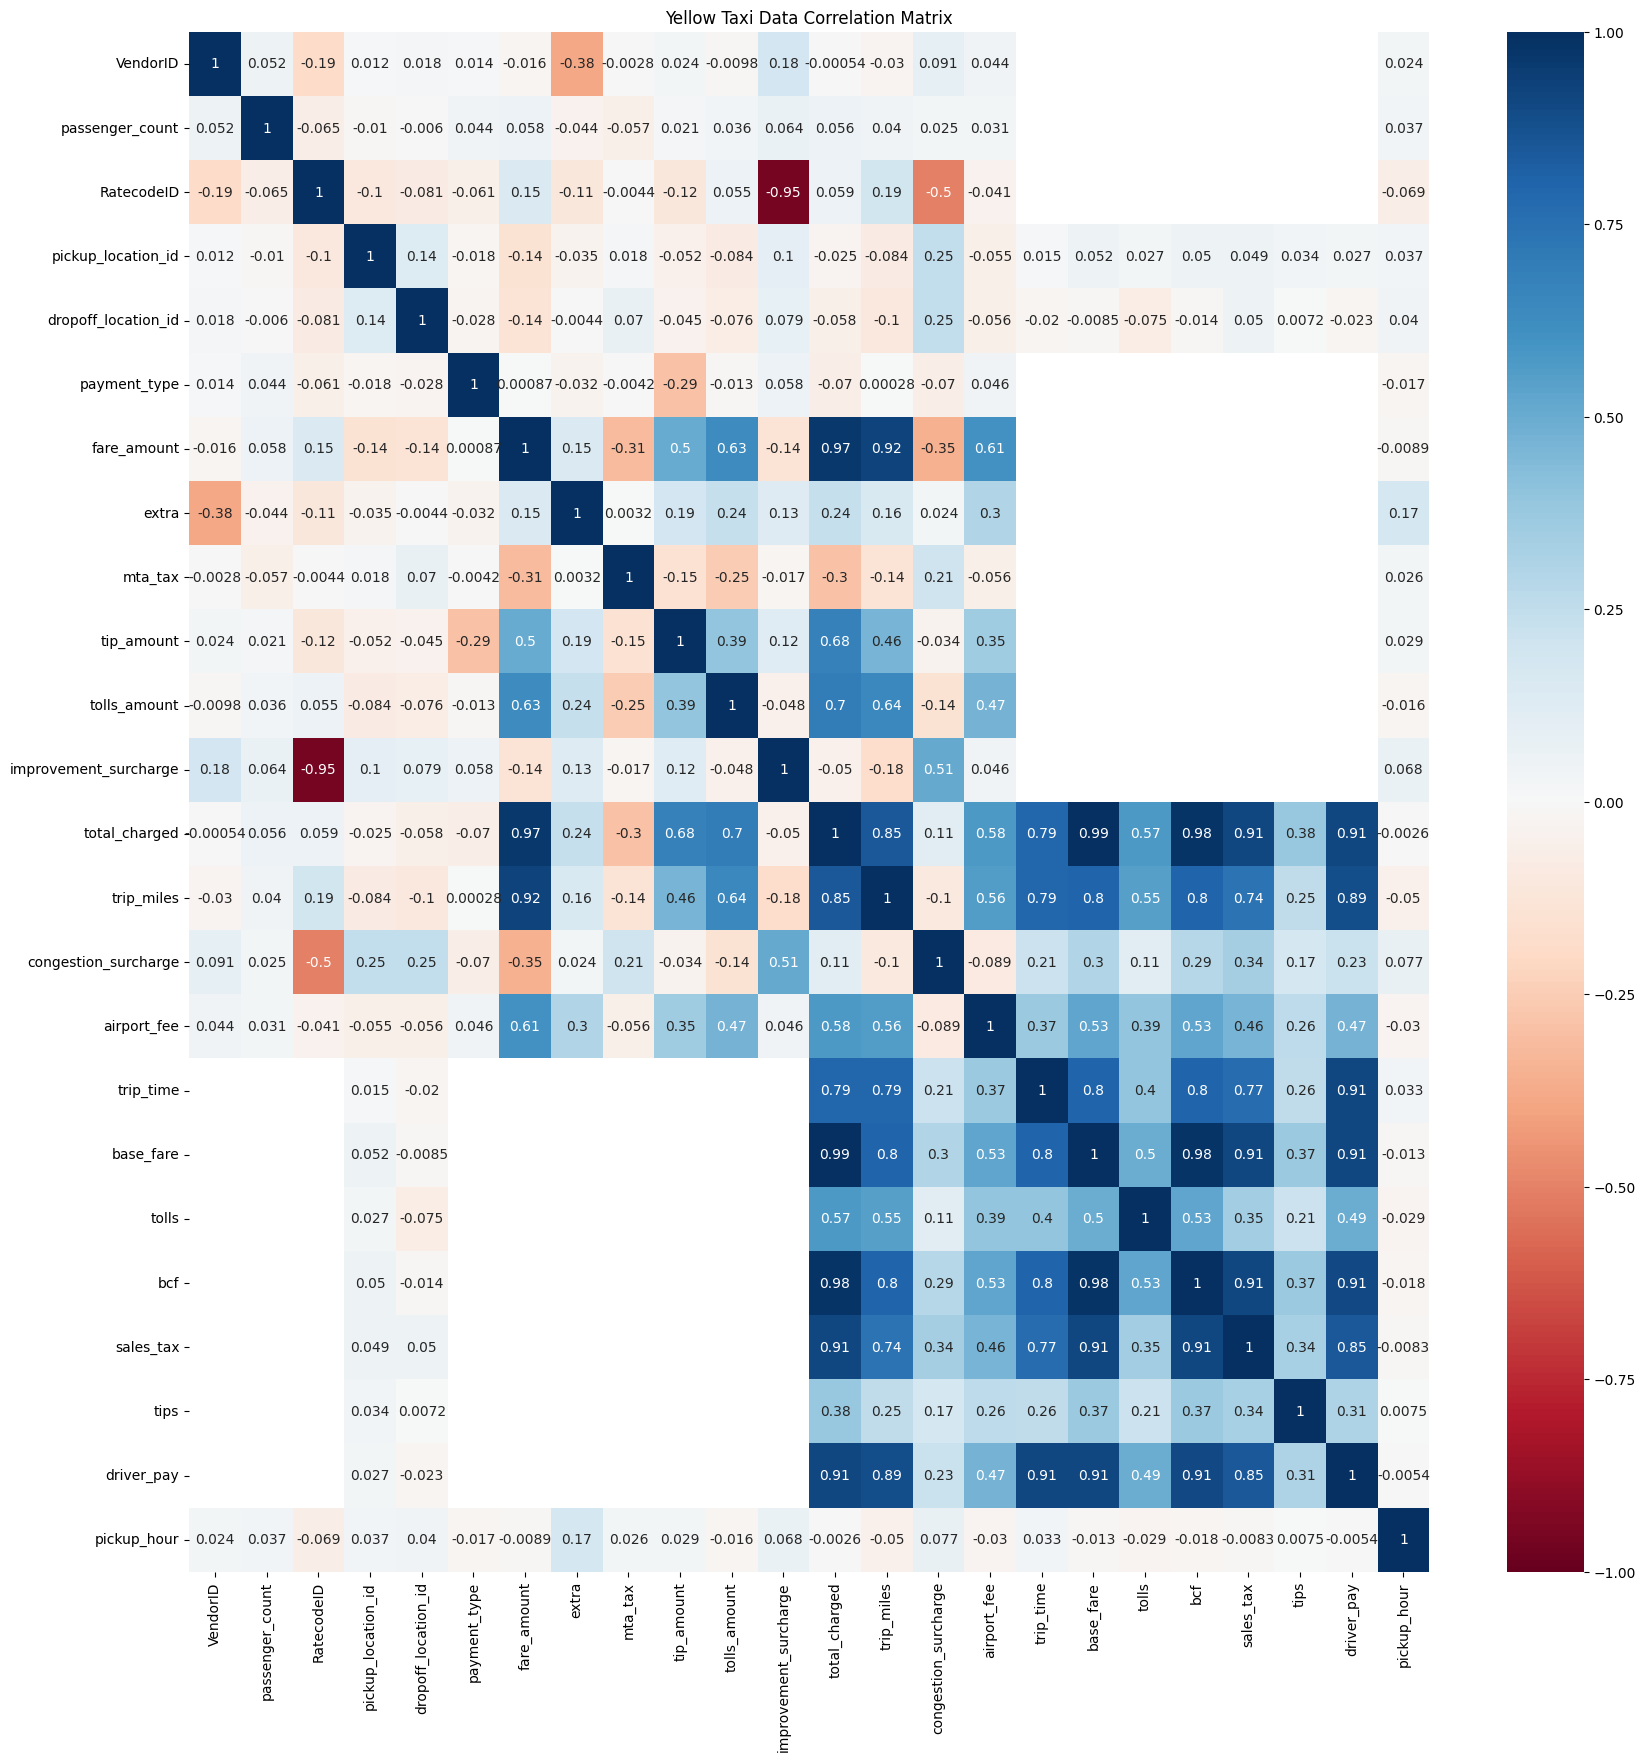

In [ ]:
corr_mat = df_cleaned.corr(numeric_only=True)
plt.figure(figsize=(20,20))
sns.heatmap(corr_mat, cmap="RdBu", annot=True, vmin = -1, vmax=1, center =0)
plt.title("Yellow Taxi Data Correlation Matrix")

plt.show()

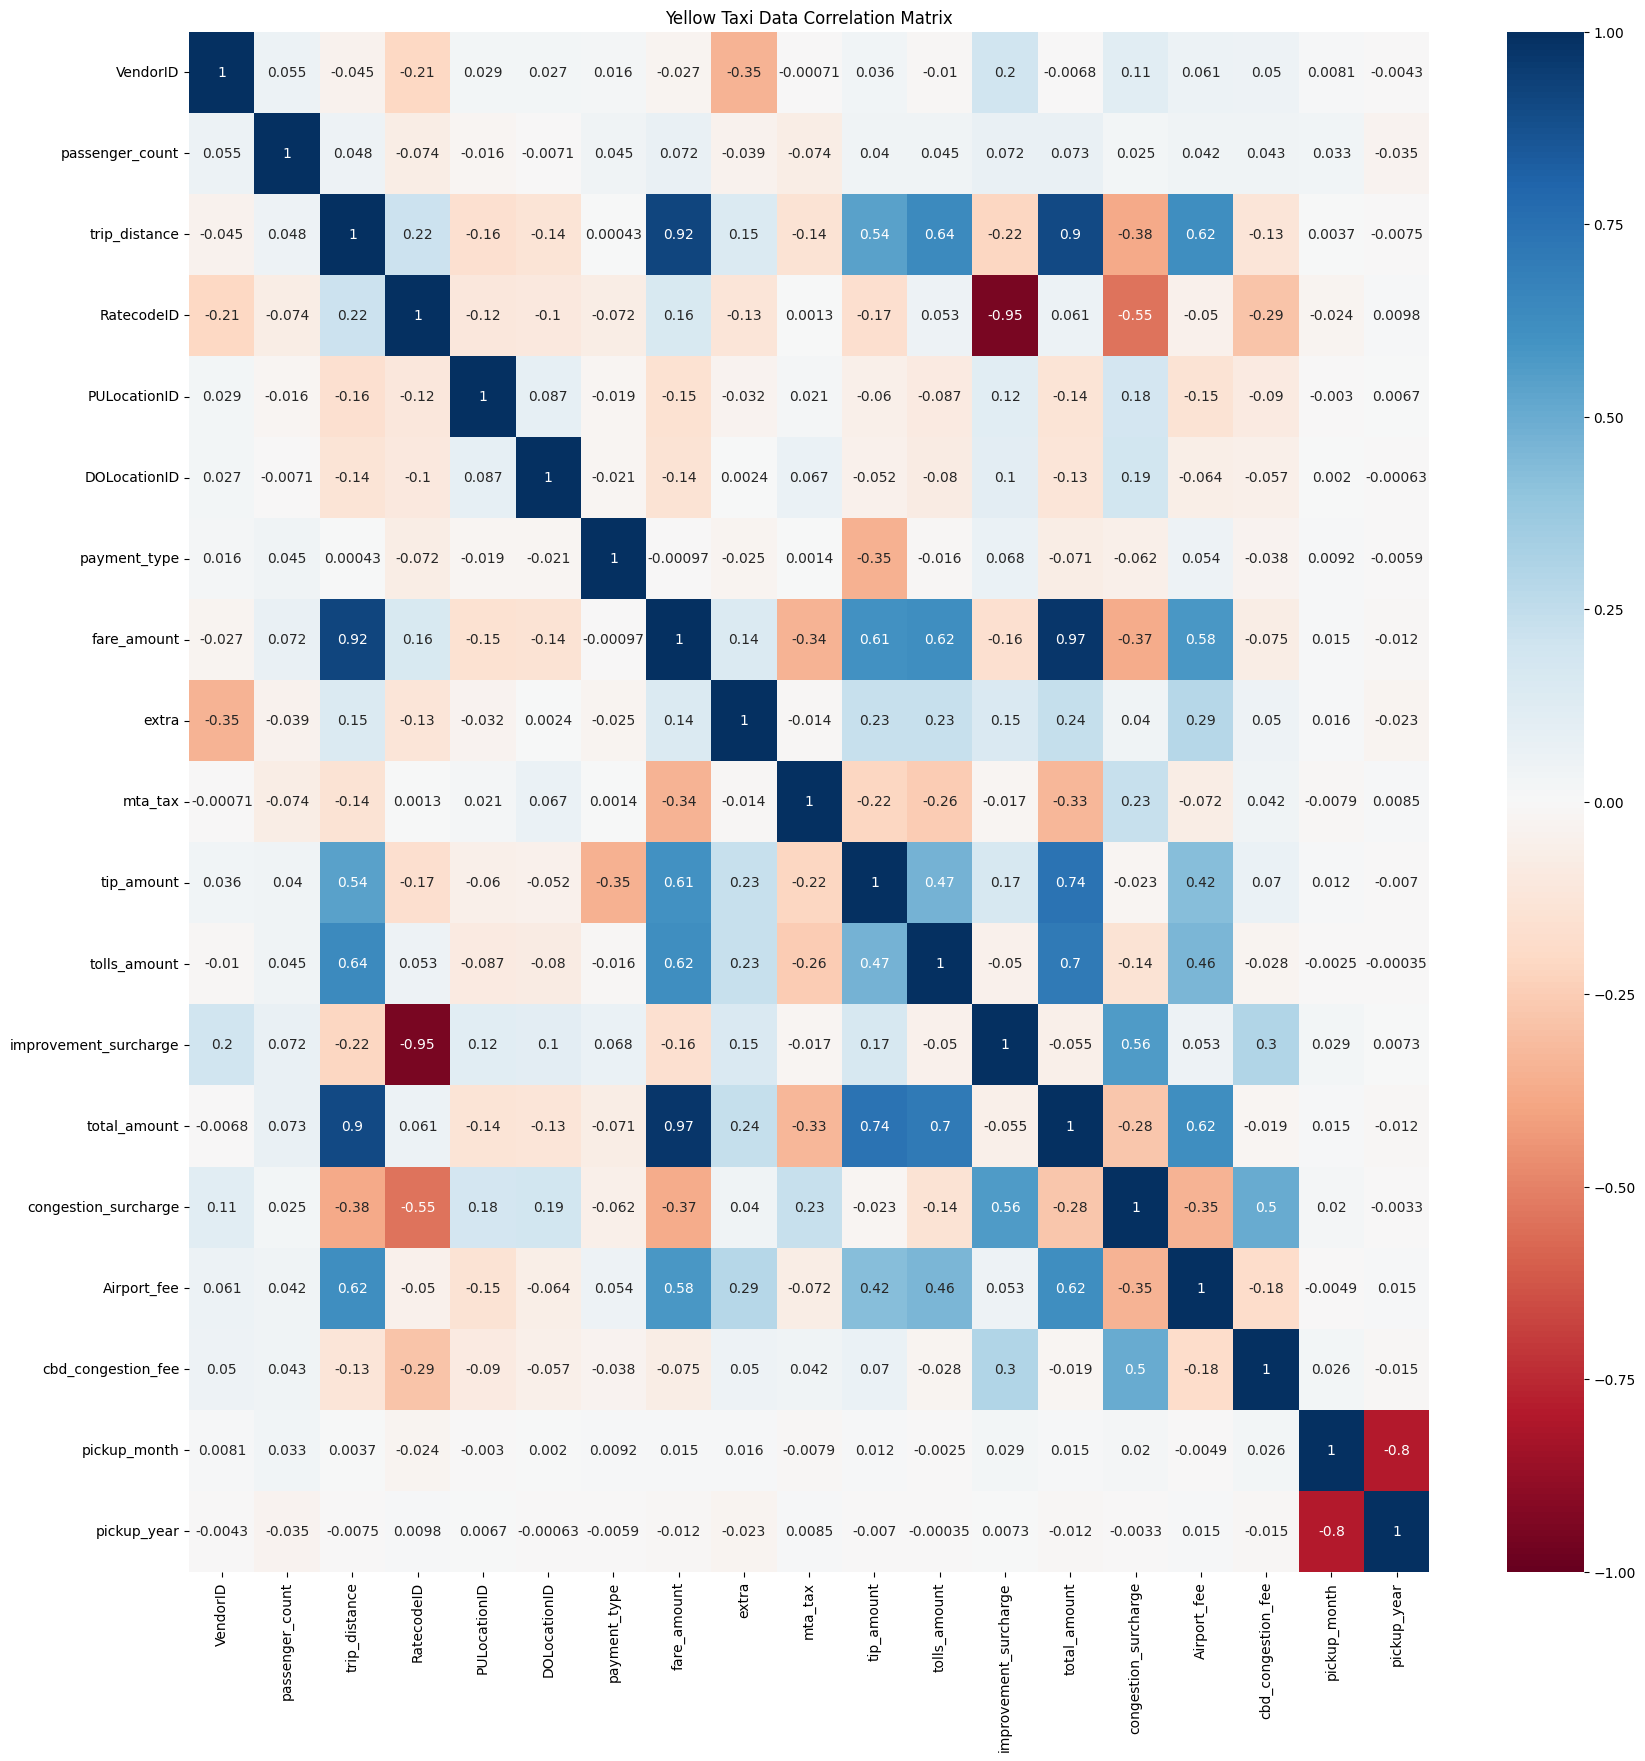

In [ ]:
# Correlation Plot
# corr_mat = df_cleaned.corr(numeric_only=True)
# plt.figure(figsize=(20,20))
# sns.heatmap(corr_mat, cmap="RdBu", annot=True, vmin = -1, vmax=1, center =0)
# plt.title("Yellow Taxi Data Correlation Matrix")

# plt.show()

Text(0.5, 0, 'Number of Passengers')

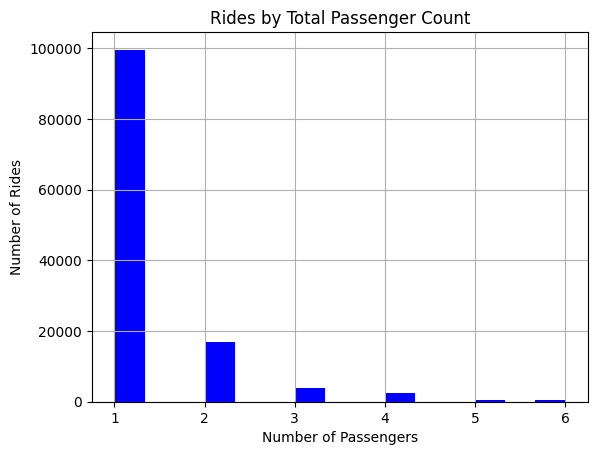

In [ ]:
df_cleaned['passenger_count'].hist(bins=15, color='blue')
plt.title("Rides by Total Passenger Count")
plt.ylabel("Number of Rides")
plt.xlabel("Number of Passengers")


In [ ]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249132 entries, 0 to 249131
Data columns (total 38 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   service_type           249132 non-null  object        
 1   VendorID               124132 non-null  Int32         
 2   passenger_count        124132 non-null  Int64         
 3   RatecodeID             124132 non-null  Int64         
 4   store_and_fwd_flag     124132 non-null  object        
 5   pickup_datetime        249132 non-null  datetime64[us]
 6   dropoff_datetime       249132 non-null  datetime64[us]
 7   pickup_location_id     249132 non-null  int32         
 8   dropoff_location_id    249132 non-null  int32         
 9   payment_type           124132 non-null  Int64         
 10  fare_amount            124132 non-null  float64       
 11  extra                  124132 non-null  float64       
 12  mta_tax                124132 non-null  floa

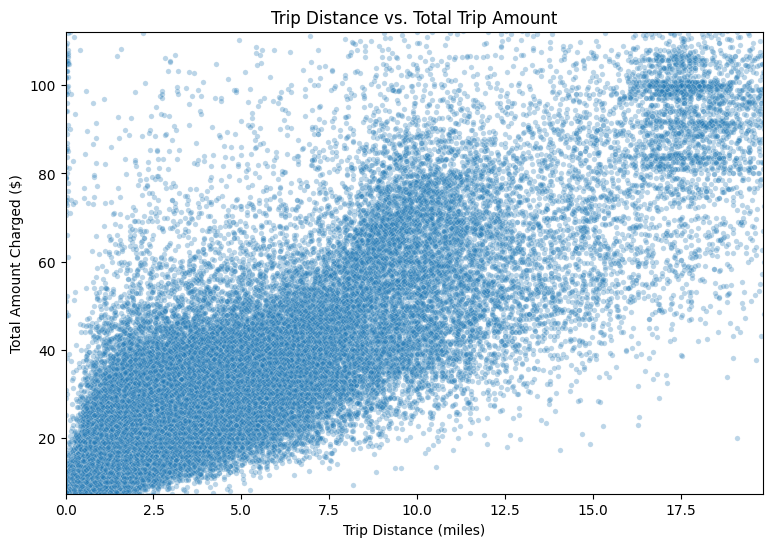

In [ ]:
#Correlation plot between trip distance and total trip amount
sample_df = df_cleaned.sample(n=min(100_000, len(df_cleaned)), random_state=42)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    sample_df,
    x="trip_miles",
    y="total_charged",
    alpha=0.3,
    s=15
)

plt.title("Trip Distance vs. Total Trip Amount")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Total Amount Charged ($)")
plt.xlim(0, sample_df["trip_miles"].quantile(0.99))
plt.ylim(
    sample_df["total_charged"].quantile(0.01),
    sample_df["total_charged"].quantile(0.99)
)

plt.show()

In [ ]:
#Pickup times and drop off times
df_cleaned["pickup_datetime"] = pd.to_datetime(
    df_cleaned["pickup_datetime"],
    errors="coerce"
)

df_cleaned["pickup_hour"] = df_cleaned["pickup_datetime"].dt.hour

hourly = (
    df_cleaned.groupby("pickup_hour")
      .agg(
          trip_count=("total_amount", "size"),
          avg_total_amount=("total_amount", "mean"),
          median_total_amount=("total_amount", "median")
      )
      .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=hourly, x="pickup_hour", y="trip_count", ax=axes[0])
axes[0].set_title("Number of Trips by Pickup Hour")
axes[0].set_xlabel("Hour of Day")

sns.lineplot(
    data=hourly,
    x="pickup_hour",
    y="median_total_amount",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Median Trip Amount by Pickup Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Median Amount ($)")

plt.tight_layout()
plt.show()

KeyError: "Column(s) ['total_amount'] do not exist"

# Do we need spark?

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("TaxiFarePrediction") \
    .getOrCreate()

df = spark.read.parquet("taxi_ml_data.parquet")

# Machine Learning

## Importing Machine Learning Packages

In [ ]:
# importing machine learning packages
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (mean_squared_error, r2_score, classification_report)

## One Hot Encoding

## PCA

In [ ]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249550 entries, 0 to 249549
Data columns (total 37 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   service_type           249550 non-null  object        
 1   VendorID               124553 non-null  Int32         
 2   passenger_count        124553 non-null  Int64         
 3   RatecodeID             124553 non-null  Int64         
 4   store_and_fwd_flag     124553 non-null  object        
 5   pickup_datetime        249550 non-null  datetime64[us]
 6   dropoff_datetime       249550 non-null  datetime64[us]
 7   pickup_location_id     249550 non-null  int32         
 8   dropoff_location_id    249550 non-null  int32         
 9   payment_type           124553 non-null  Int64         
 10  fare_amount            124553 non-null  float64       
 11  extra                  124553 non-null  float64       
 12  mta_tax                124553 non-null  floa

In [ ]:
df_cleaned.head()

,service_type,VendorID,passenger_count,RatecodeID,store_and_fwd_flag,pickup_datetime,dropoff_datetime,pickup_location_id,dropoff_location_id,payment_type,...,tolls,bcf,sales_tax,tips,driver_pay,shared_request_flag,shared_match_flag,access_a_ride_flag,wav_request_flag,wav_match_flag
0,yellow,2,2,1,N,2024-08-23 11:51:04,2024-08-23 12:07:32,246,161,1,...,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None
1,yellow,2,1,1,N,2024-08-08 07:31:06,2024-08-08 07:41:41,142,161,1,...,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None
2,yellow,2,2,1,N,2024-08-06 23:03:30,2024-08-06 23:15:47,230,158,1,...,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None
3,yellow,2,3,1,N,2024-08-26 18:18:00,2024-08-26 18:20:05,237,237,1,...,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None
4,yellow,2,2,1,N,2024-08-13 08:10:09,2024-08-13 08:17:20,164,246,1,...,NaN,NaN,NaN,NaN,NaN,None,None,None,None,None


In [ ]:
# Features dataframe into variable called "features"
features = df_cleaned.drop(columns = ["service_type", "total_charged", "pickup_datetime", "dropoff_datetime", 'request_datetime','on_scene_datetime'])

# TO-DO: store the classification target variable into "target"
target = df_cleaned['total_charged']
target

,total_charged
0,23.52
1,20.16
2,21.20
3,13.92
4,15.12
...,...
249545,36.49
249546,32.13
249547,15.98
249548,66.79


In [ ]:
# Assign appropriate value to seed and conduct 80/20 train-test split with random_state = seed
seed = 42
X_train, X_test, y_train, y_test = train_test_split(features,target, test_size = 0.2, random_state = seed)

In [ ]:
#Get the numeric columns
# numeric_cols = df_cleaned.select_dtypes(include=["int64", "float64", "int32"]).columns
# X = df_cleaned[numeric_cols]

In [ ]:
# Standardize the data
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

In [ ]:
# TO-DO: Intermediate step to address fact that PCA is not scale-invariant
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# TO-DO: Instantiate and Fit PCA
pca = PCA(n_components=10, random_state=42)
pca.fit(X_train_scaled)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

ValueError: could not convert string to float: 'N'

In [ ]:
# TO-DO: Save the explained variance ratios into variable called "explained_variance_ratios"
explained_variance_ratios = pca.explained_variance_ratio_
explained_variance_ratios

# TO-DO: Save the CUMULATIVE explained variance ratios into variable called "cum_evr"
cum_evr = np.cumsum(pca.explained_variance_ratio_)
cum_evr

In [ ]:
# TO-DO: find optimal num components to use (n) by plotting explained variance ratio (2 points)
components = np.arange(1, len(explained_variance_ratios) + 1)
plt.figure(figsize=(10,6))
plt.plot(components, cum_evr, marker = "o" , linestyle = "-")
plt.axhline(y=0.80, color="darkred", linestyle="--", alpha = 0.8, label = "80% variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.xticks(components)
plt.legend(loc="lower right")
plt.title("Cumulative Explained Variance Ratio Plot")
plt.show()

## Linear Regression (non-scaled)

In [ ]:
# Initialize model with default parameters and fit it on the training set
reg = LinearRegression()
reg.fit(X_train, y_train)

# Use the model to predict on the test set and save these predictions as `y_pred`
y_pred = reg.predict(X_test)

# Find the R-squared score and store the value in `lin_reg_score`
lin_reg_score = reg.score(X_test, y_test)

## Ridge Regression

In [ ]:
# TO-DO: Intermediate step to address scale-invariance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# TO-DO: Import required libraries
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

# TO-DO: Initialize model with alpha = 10 (keep other hyperparameters as default values) and fit it on the training set
reg_ridge = Ridge(alpha = 10)

# TO-DO: Use the model to predict on the test set and save these predictions as `y_pred
reg_ridge.fit(X_train_scaled, y_train)
y_pred = reg_ridge.predict(X_train_scaled)

# TO-DO: Find the R-squared score and store the value in `ridge_score`
ridge_score = reg_ridge.score(X_test_scaled, y_test)